# Rule space

## Setup

In [1]:
from pathlib import Path
import sys

import pandas as pd

ROOT = next(
    folder for folder in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (folder / "result_summary" / "data_helper.py").exists()
)
sys.path[:0] = [str(ROOT / "result_summary"), str(ROOT / "result_summary" / "rule_space")]

import data_helper as dh
import final_figures_vis as fv
import rule_space_helper as rs
import vis_helper as vh

In [2]:
STAGES = ["Control", "Severe"]
EXCLUDE = ["Muscle"]
MIN_FOV = 0.05
N_SPREAD = 7
N_LOADINGS = 8
N_TOP = 10
WIDTH = 15
FONT_SIZE = 20

rs.METRIC = "Lift"
rs.POSITIVE_ONLY = False
rs.RULE_MAX_ITEMS = 2
rs.NO_SELF = False

## Data

In [3]:
data = rs.load()
cell_colors = vh.set_cell_colors(data.cells)
NO_RULES = pd.DataFrame(columns=["FOV", "center", "neighbor"])

Dropped 21 FOVs: Control_S
Loaded 598093 cells; FOVs: 267, biopsies: 73, patients: 71
Read results_CN_pairwise.csv + results_CN_complex.csv
Loaded 758621 rules.
Kept 6978 rules at FDR <= 0.05.
Kept 6946 rules naming no Unidentified.
Kept 6946 rules (max_items=4, kind=None).


## Keys

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\stages.pdf


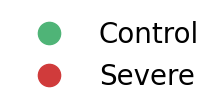

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\rule_class_tabs.pdf


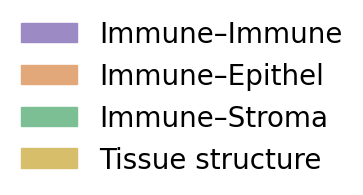

In [4]:
fv.save_stage_key(STAGES, FONT_SIZE)
fv.save_class_key(FONT_SIZE, fv.CLASS_TABS, "rule_class_tabs")

In [5]:
def rule_space(organ, score, far=None, pc=None, mark_pair=False):
    """For one organ's FOVs by `score`: the rule PCA beside the cell composition PCA, each titled by how
    well its better PC separates the STAGES (`rs.stage_auc`), with those numbers per PC and how much the
    two PCAs' components agree printed; the rule PCA, titled by its FOVs and rules, also beside the cells when `mark_pair`, with
    FOVs spread along `pc` (its better PC when None), those FOVs and the closest pair as maps, its
    loadings, banded by rule class and coloured by the kind of the rule's median lift in these FOVs, with the share of
    rules whose weight has the sign of their correlation with the PC printed, and one cell type key. Rules and
    cells of EXCLUDE are left out. With `far`, all of it without the FOVs over `far` times the usual distance from
    the PCA's middle."""
    rs.SCORE_COL = score
    name = f"rule_space_{organ}_{score.split()[0]}" + ("_no_outliers" if far else "")
    fit = lambda fovs=None: rs.run(data, stages=STAGES, organs=[organ], exclude=EXCLUDE,
                                   min_fov=MIN_FOV, fovs=fovs, diagnostics=False)
    scope = fit()
    if far:
        scope = fit(rs.outliers(scope, far)[0])
    pcas = {"Rules": scope, "Cells": rs.composition_pca(data, scope, exclude=EXCLUDE)}
    aucs = pd.DataFrame({what: {pc: rs.stage_auc(pca, pc, *STAGES) for pc in ("PC1", "PC2")}
                         for what, pca in pcas.items()})
    print(f"{' vs '.join(STAGES)} AUC per PC:")
    print(aucs.round(2))
    print("Agreement, rule PCs (rows) with cell PCs (columns), |rho|:")
    print(rs.agreement(*pcas.values()).round(2))
    pc = pc or aucs["Rules"].idxmax()
    path, line = rs.spread_from(scope, pc, N_SPREAD, *STAGES)
    tags = fv.stage_tags(STAGES, len(path))
    rows = {"spread": path, "pair": rs.closest_pair(scope)}
    row_tags = {"spread": tags, "pair": []}
    marks = {"marked": dict(zip(path, tags)), "pair": rows["pair"], "line": line}

    fv.plot_pca_pair({f"{what} · AUC {aucs[what].max():.2f}": (pca.coords, pca.variance) for what, pca in pcas.items()},
                     score, width=WIDTH, font_size=FONT_SIZE, **marks if mark_pair else {},
                     save=f"{name}_rules_vs_cells")
    fv.plot_pca(scope.coords, scope.variance, score, **marks, width=WIDTH, font_size=FONT_SIZE,
                title=f"{organ} | {len(scope.coords)} FOVs × {scope.matrix.shape[1]} rules", save=f"{name}_pca")
    for row, shown in rows.items():
        fv.plot_fov_maps(data.cells, shown, cell_colors, None,
                         width=WIDTH * len(shown) / N_SPREAD, font_size=FONT_SIZE, tags=row_tags[row],
                         save=f"{name}_{row}_maps")
    weights = scope.model.components_[:2]
    places = scope.coords.set_index("FOV")
    print("Loadings agree with the PCA (share of rules):",
          {pc: (scope.matrix.corrwith(places[pc]).gt(0) == (weight > 0)).mean() for pc, weight in zip(("PC1", "PC2"), weights)})
    found = data.results[data.results["FOV"].isin(scope.matrix.index)]
    lifts = found.groupby(found["Antecedents"].map(dh.clean_items) + " -> " + found["Consequents"].map(dh.clean_items))["Lift"].median()
    fv.plot_loadings(weights, scope.matrix.columns, N_LOADINGS, width=WIDTH, font_size=FONT_SIZE,
                     kinds=lifts.gt(1).map({True: "attracts", False: "avoids"}),
                     classes=dh.rule_class(scope.matrix.columns, data.cells), save=f"{name}_loadings")
    key = fv.key_cells(data.cells, sum(rows.values(), []), NO_RULES, N_TOP)
    fv.save_cell_key(key, cell_colors, FONT_SIZE, save=f"{name}_pca")

### Colon · Clinical score

Colon, Control vs Severe: 77 FOVs x 80 columns  |  PC1 11.6%  PC2 9.1%
Colon, Control vs Severe, cell counts without Muscle: 77 FOVs x 31 columns  |  PC1 38.0%  PC2 30.5%
Control vs Severe AUC per PC:
     Rules  Cells
PC1   0.54   0.89
PC2   0.81   0.66
Agreement, rule PCs (rows) with cell PCs (columns), |rho|:
      PC1   PC2
PC1  0.04  0.12
PC2  0.33  0.40
  pair: Control_Colon_01_FOV_4 + GVHD_01_FOV_2_R  (0.58 apart, nothing else within 0.63)
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Clinical_rules_vs_cells\rule_space_Colon_Clinical_rules_vs_cells.pdf
saved pca_1, pca_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Clinical_rules_vs_cells


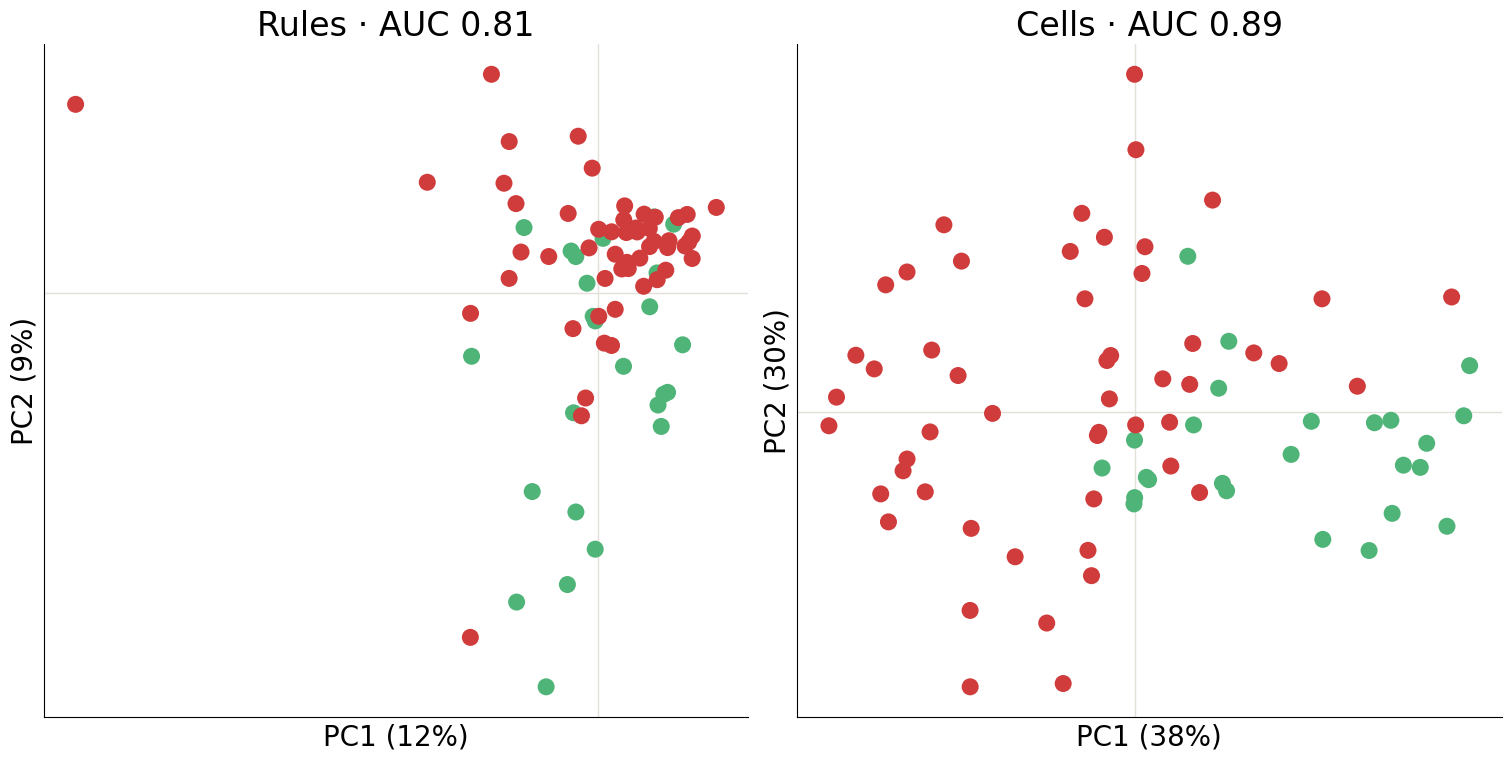

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Clinical_pca\pca.pdf


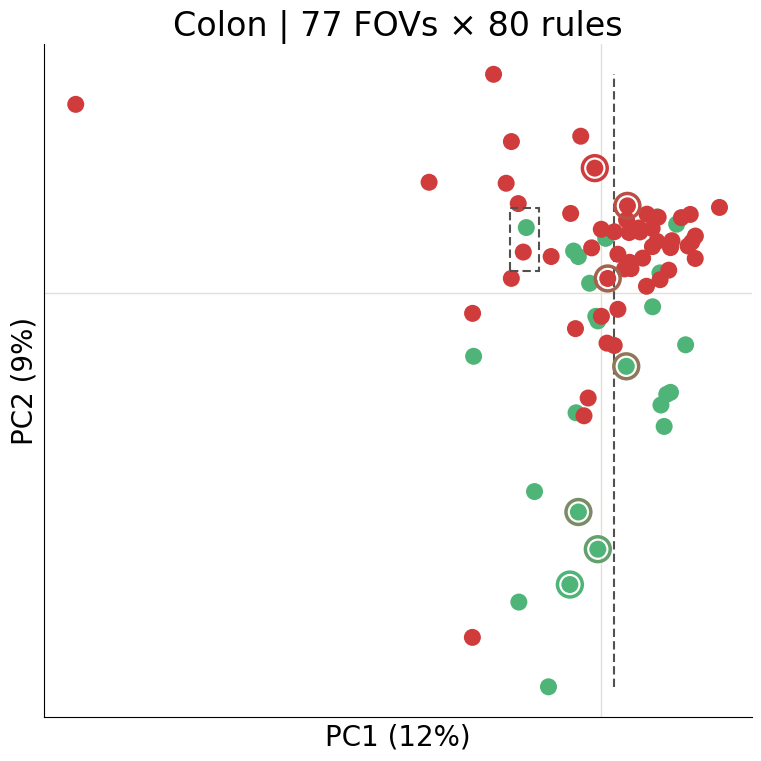

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Clinical_spread_maps\rule_space_Colon_Clinical_spread_maps.pdf
saved map_1, map_2, map_3, map_4, map_5, map_6, map_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Clinical_spread_maps


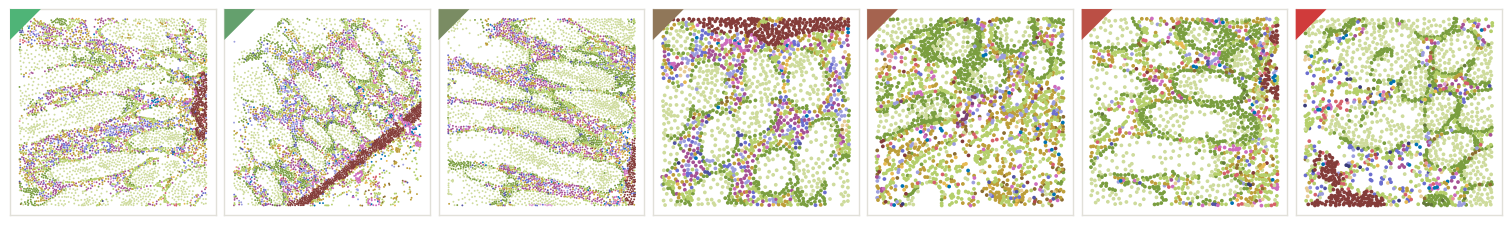

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Clinical_pair_maps\rule_space_Colon_Clinical_pair_maps.pdf
saved map_1, map_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Clinical_pair_maps


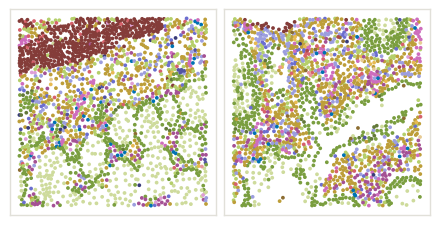

Loadings agree with the PCA (share of rules): {'PC1': np.float64(1.0), 'PC2': np.float64(1.0)}
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Clinical_loadings\rule_space_Colon_Clinical_loadings.pdf
saved pc_1, pc_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Clinical_loadings


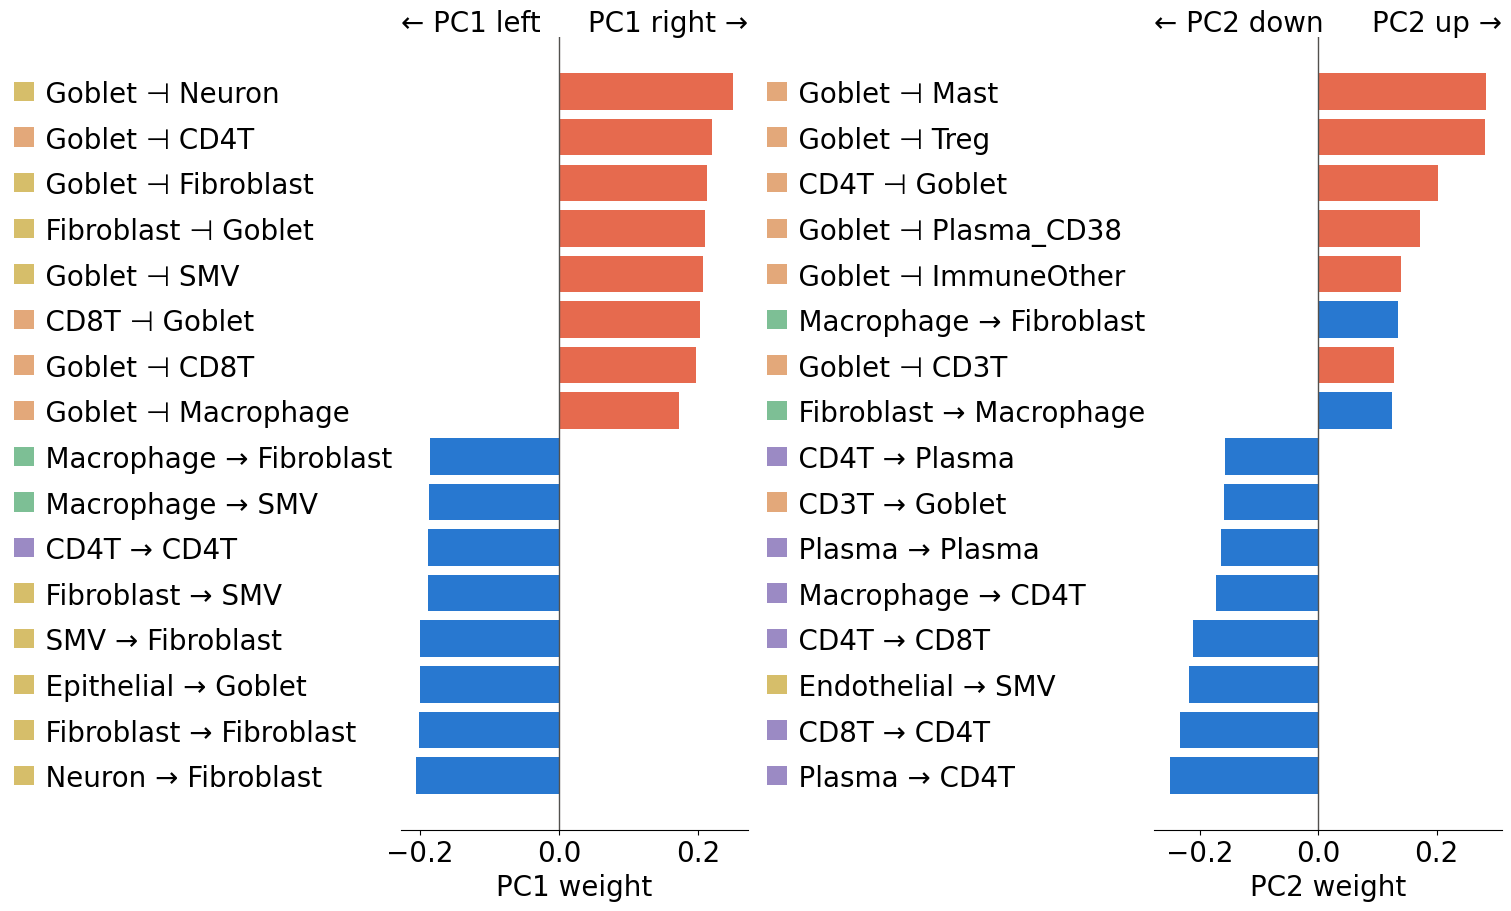

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Clinical_pca\cells.pdf


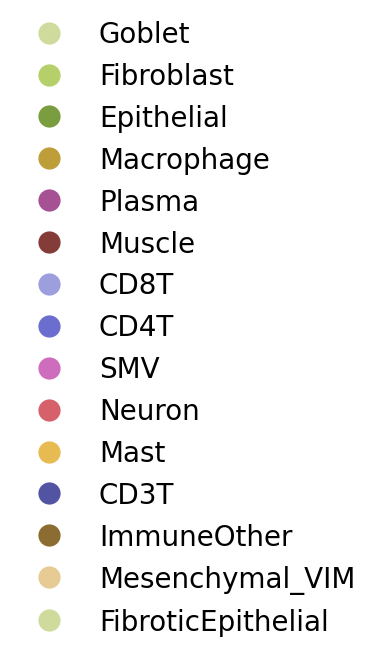

In [6]:
rule_space("Colon", "Clinical score")

### Colon · Pathological score

Colon, Control vs Severe: 57 FOVs x 86 columns  |  PC1 13.2%  PC2 10.1%
Colon, Control vs Severe, cell counts without Muscle: 57 FOVs x 31 columns  |  PC1 45.0%  PC2 25.2%
Control vs Severe AUC per PC:
     Rules  Cells
PC1   0.75   0.93
PC2   0.83   0.59
Agreement, rule PCs (rows) with cell PCs (columns), |rho|:
      PC1   PC2
PC1  0.37  0.26
PC2  0.51  0.16
  pair: Control_Colon_01_FOV_4 + GVHD_01_FOV_2_R  (0.53 apart, nothing else within 0.89)
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Pathological_rules_vs_cells\rule_space_Colon_Pathological_rules_vs_cells.pdf
saved pca_1, pca_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Pathological_rules_vs_cells


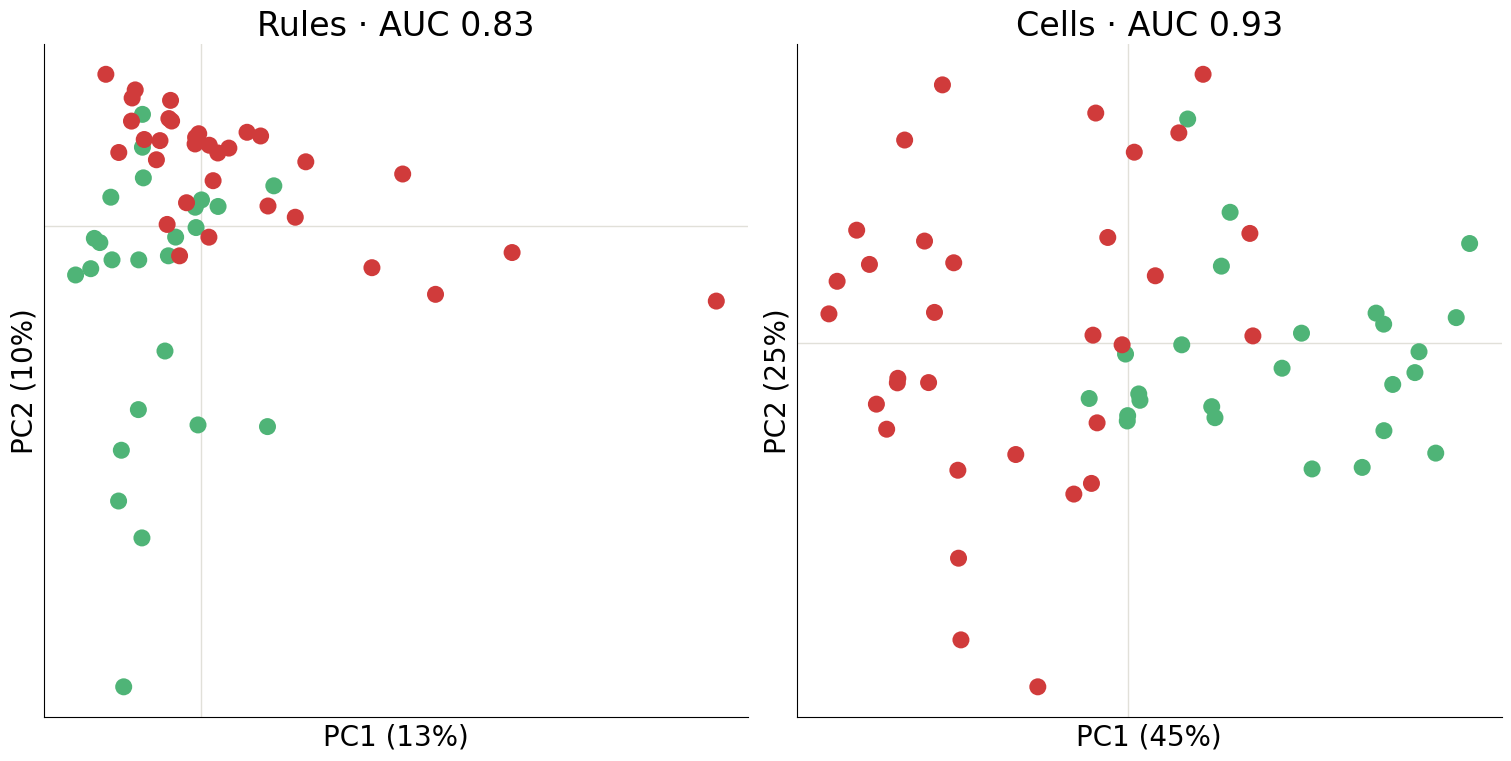

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Pathological_pca\pca.pdf


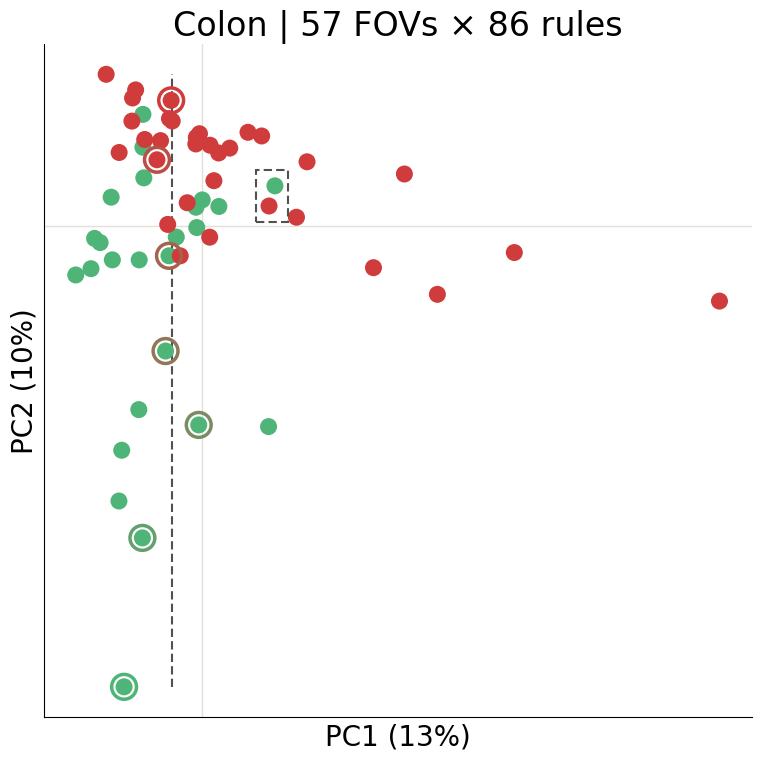

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Pathological_spread_maps\rule_space_Colon_Pathological_spread_maps.pdf
saved map_1, map_2, map_3, map_4, map_5, map_6, map_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Pathological_spread_maps


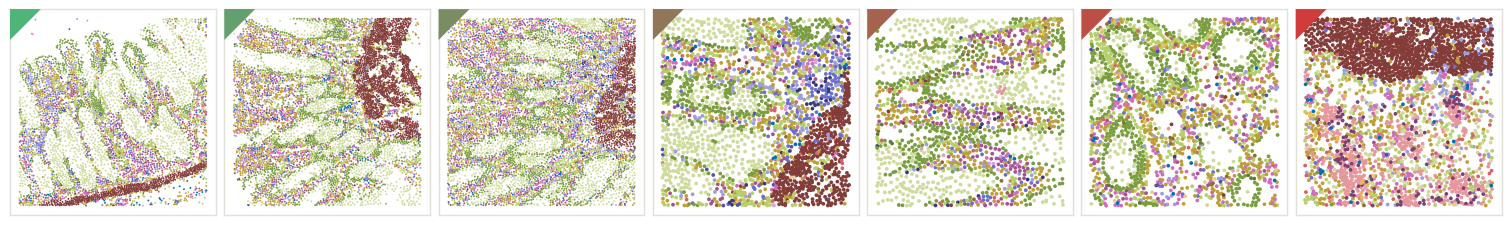

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Pathological_pair_maps\rule_space_Colon_Pathological_pair_maps.pdf
saved map_1, map_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Pathological_pair_maps


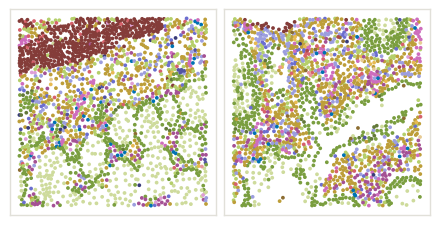

Loadings agree with the PCA (share of rules): {'PC1': np.float64(1.0), 'PC2': np.float64(1.0)}
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Pathological_loadings\rule_space_Colon_Pathological_loadings.pdf
saved pc_1, pc_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Pathological_loadings


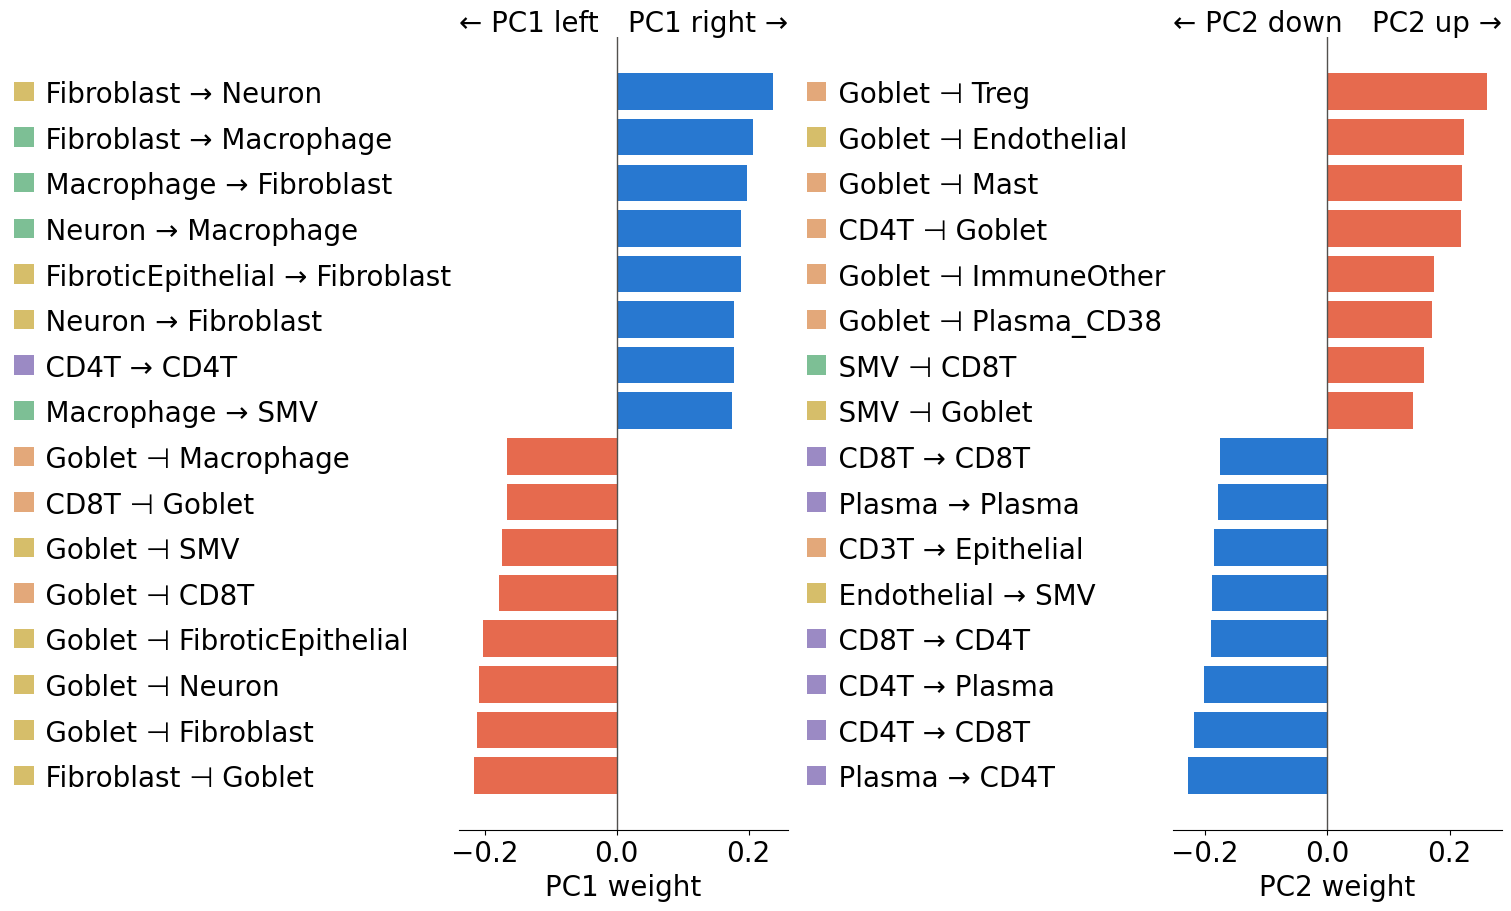

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Colon_Pathological_pca\cells.pdf


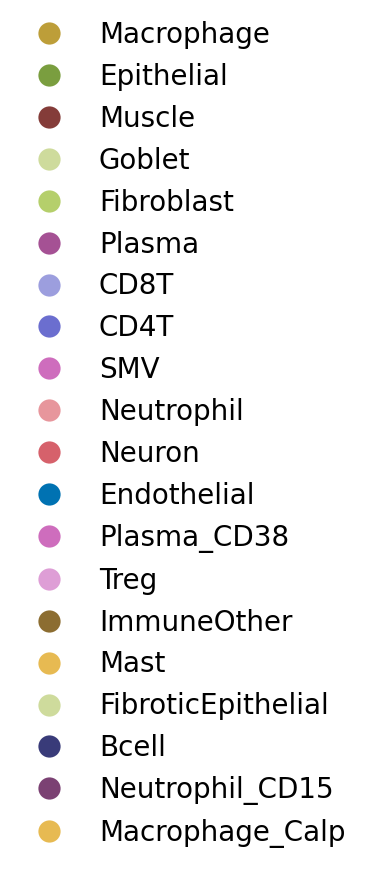

In [7]:
rule_space("Colon", "Pathological score")

### Duodenum · Clinical score

Duodenum, Control vs Severe: 69 FOVs x 74 columns  |  PC1 15.4%  PC2 7.6%
Duodenum, Control vs Severe, cell counts without Muscle: 69 FOVs x 31 columns  |  PC1 72.9%  PC2 7.2%
Control vs Severe AUC per PC:
     Rules  Cells
PC1   0.64   0.76
PC2   0.65   0.88
Agreement, rule PCs (rows) with cell PCs (columns), |rho|:
      PC1  PC2
PC1  0.77  0.0
PC2  0.21  0.3
  pair: Control_03_FOV_3 + Control_05_FOV_2  (0.37 apart, nothing else within 0.65)
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Clinical_rules_vs_cells\rule_space_Duodenum_Clinical_rules_vs_cells.pdf
saved pca_1, pca_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Clinical_rules_vs_cells


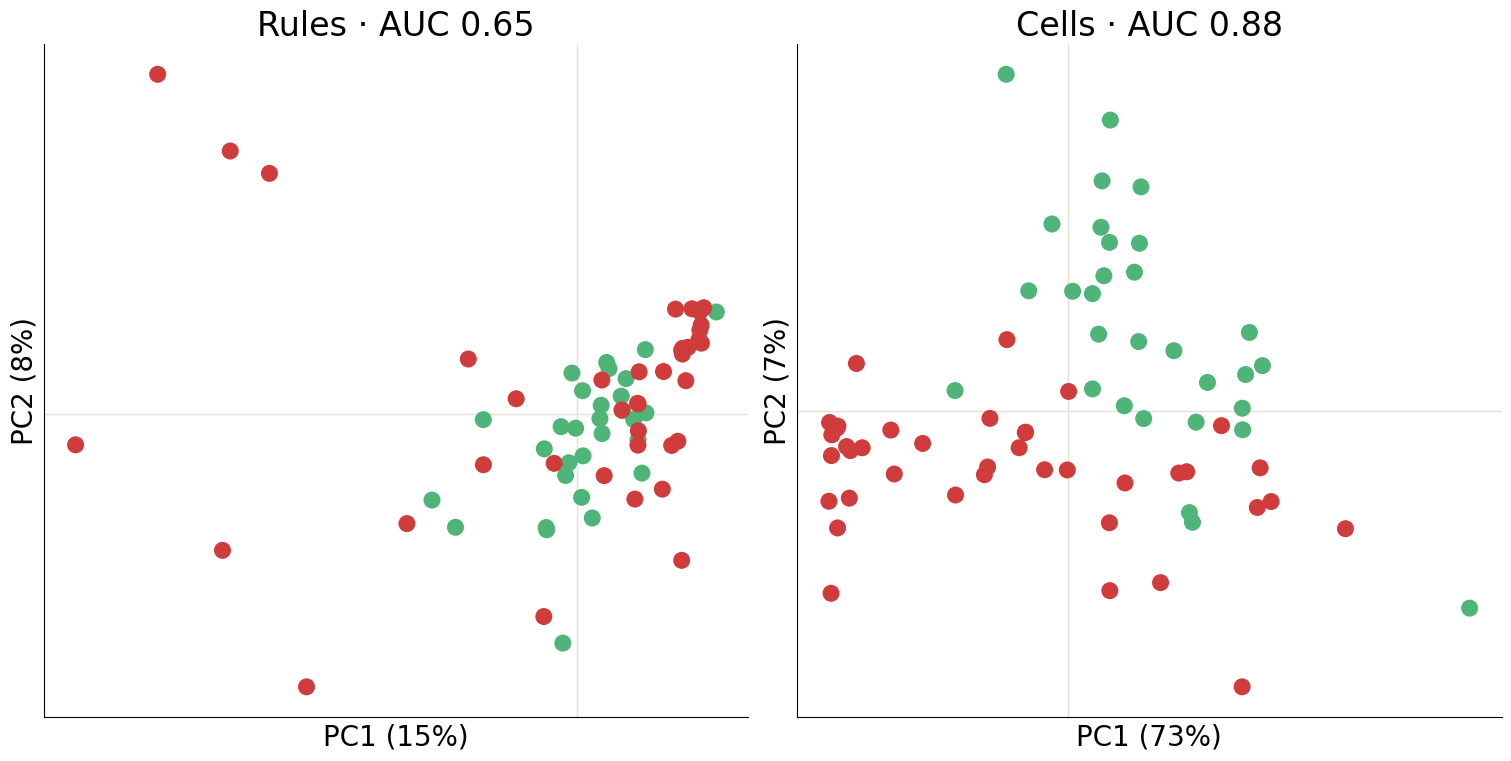

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Clinical_pca\pca.pdf


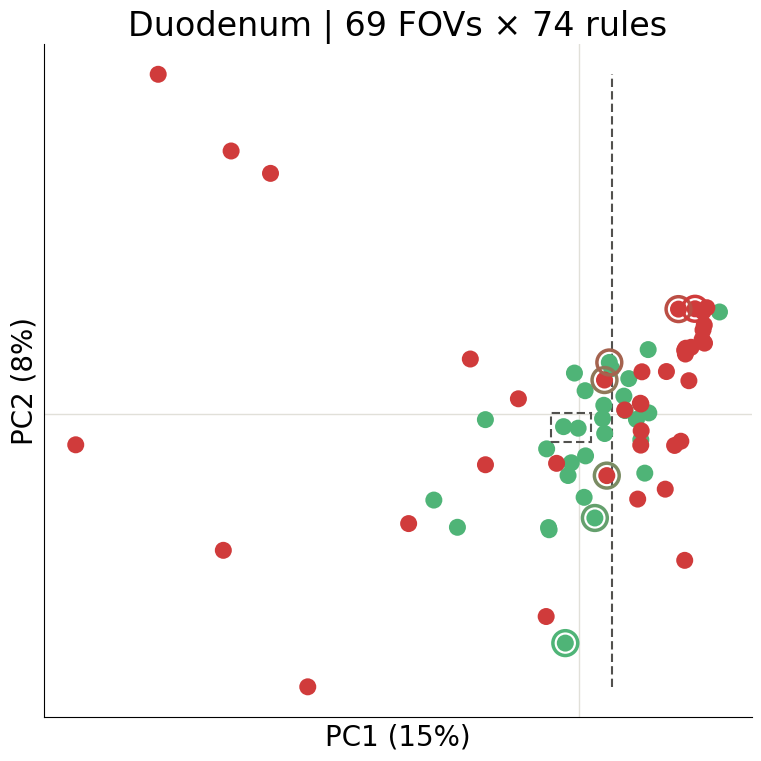

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Clinical_spread_maps\rule_space_Duodenum_Clinical_spread_maps.pdf
saved map_1, map_2, map_3, map_4, map_5, map_6, map_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Clinical_spread_maps


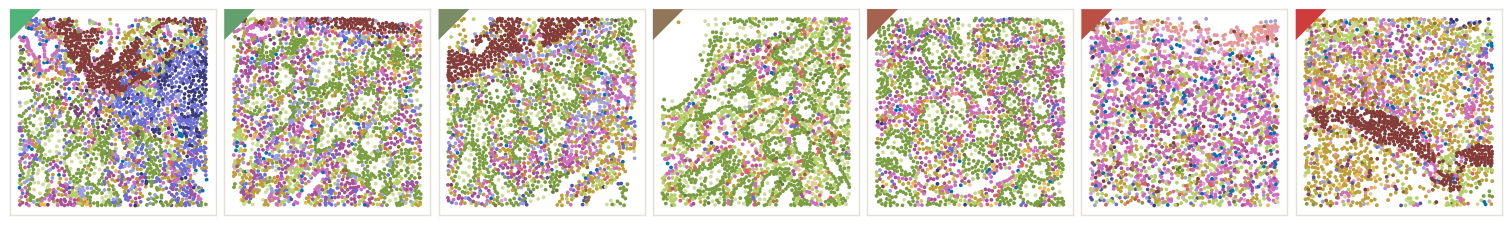

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Clinical_pair_maps\rule_space_Duodenum_Clinical_pair_maps.pdf
saved map_1, map_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Clinical_pair_maps


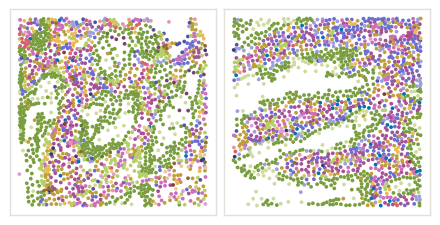

Loadings agree with the PCA (share of rules): {'PC1': np.float64(1.0), 'PC2': np.float64(1.0)}
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Clinical_loadings\rule_space_Duodenum_Clinical_loadings.pdf
saved pc_1, pc_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Clinical_loadings


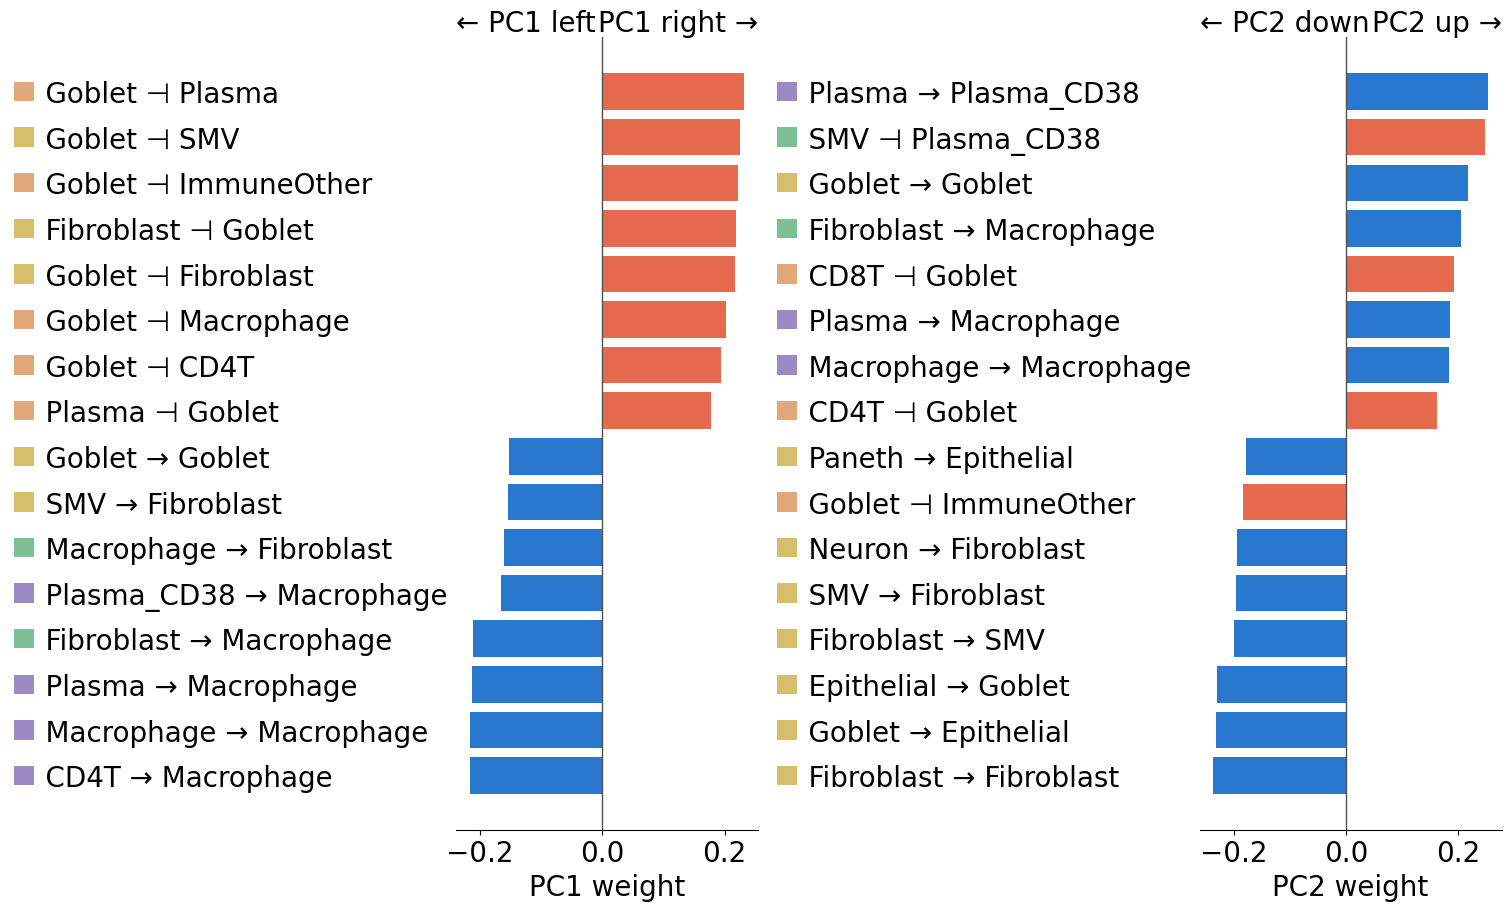

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Clinical_pca\cells.pdf


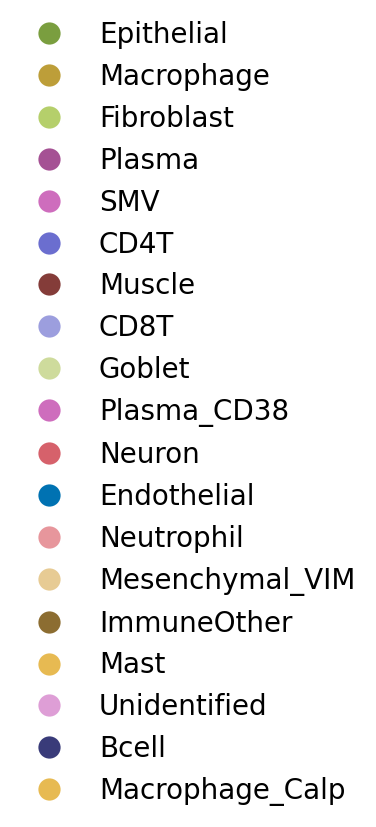

In [8]:
rule_space("Duodenum", "Clinical score")

### Duodenum · Pathological score

Duodenum, Control vs Severe: 62 FOVs x 63 columns  |  PC1 16.0%  PC2 9.1%
Duodenum, Control vs Severe, cell counts without Muscle: 62 FOVs x 31 columns  |  PC1 71.0%  PC2 9.3%
Control vs Severe AUC per PC:
     Rules  Cells
PC1   0.78   0.81
PC2   0.85   0.73
Agreement, rule PCs (rows) with cell PCs (columns), |rho|:
      PC1   PC2
PC1  0.81  0.09
PC2  0.37  0.32
  pair: Control_03_FOV_2 + Control_10_FOV_2  (0.54 apart, nothing else within 0.70)
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_rules_vs_cells\rule_space_Duodenum_Pathological_rules_vs_cells.pdf
saved pca_1, pca_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_rules_vs_cells


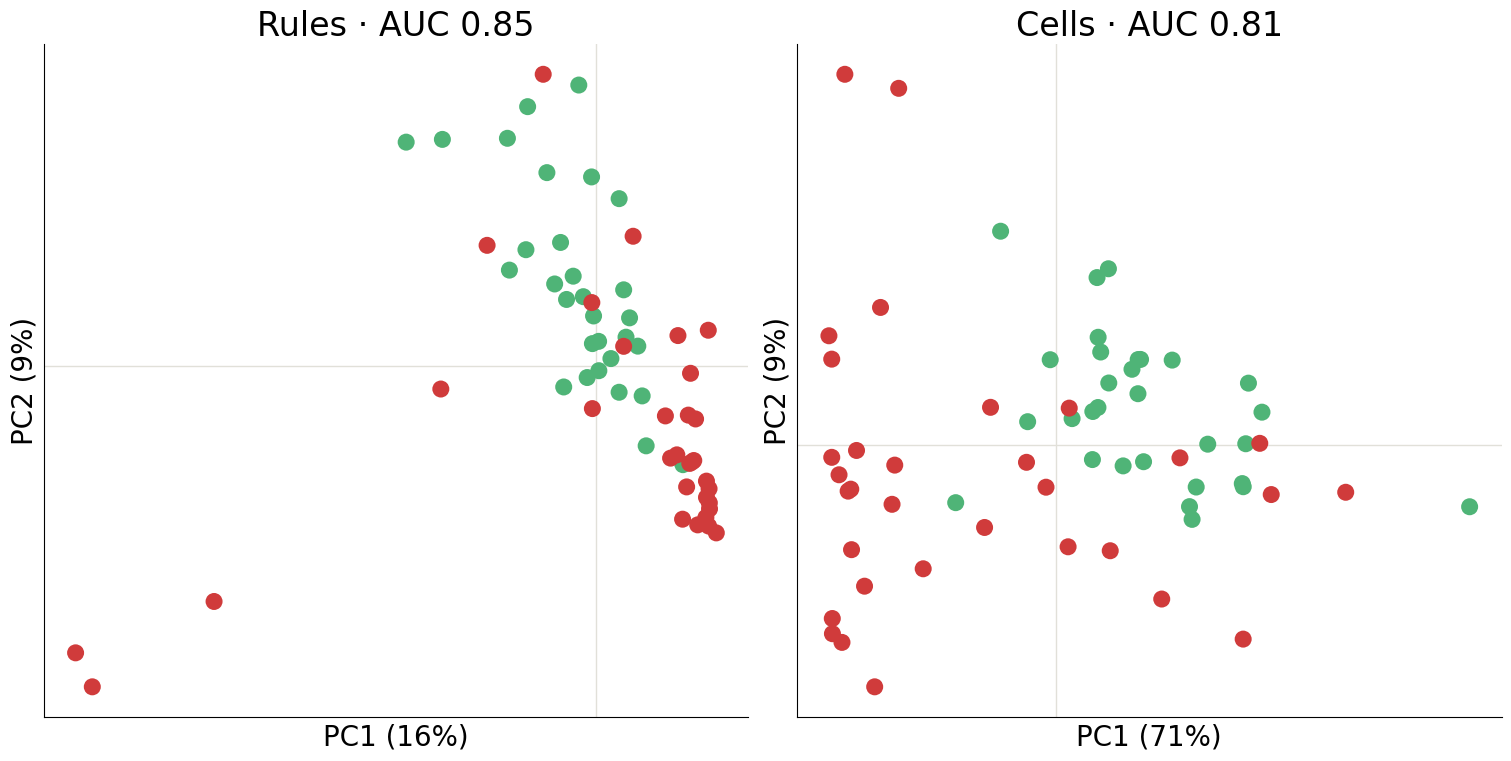

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_pca\pca.pdf


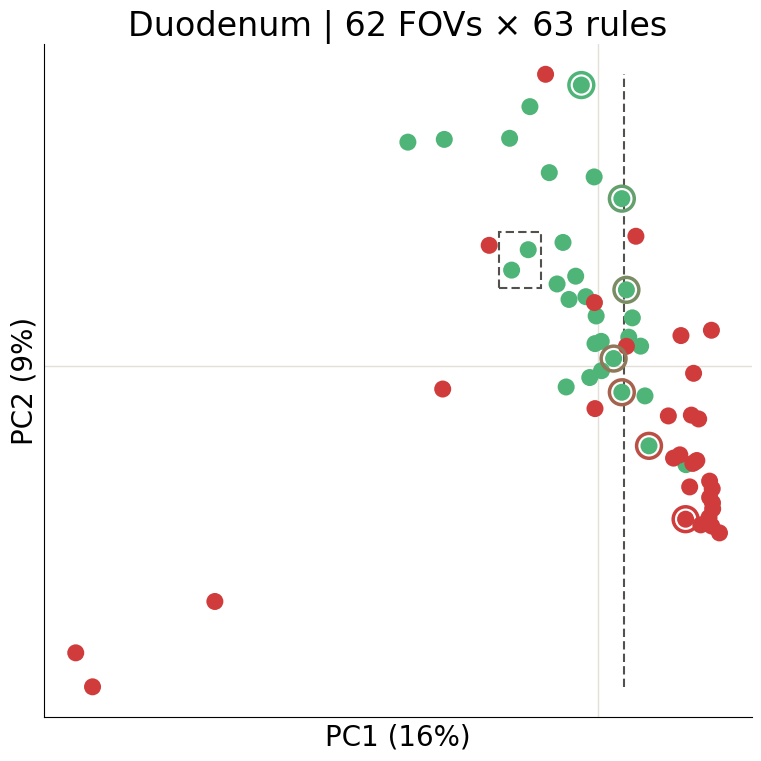

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_spread_maps\rule_space_Duodenum_Pathological_spread_maps.pdf
saved map_1, map_2, map_3, map_4, map_5, map_6, map_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_spread_maps


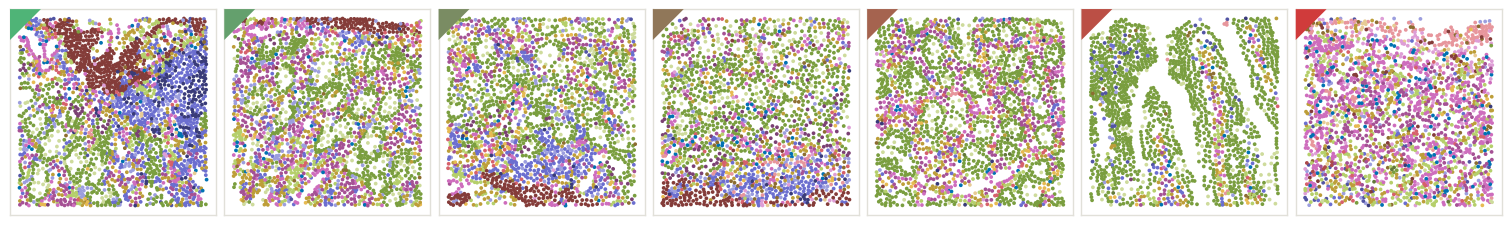

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_pair_maps\rule_space_Duodenum_Pathological_pair_maps.pdf
saved map_1, map_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_pair_maps


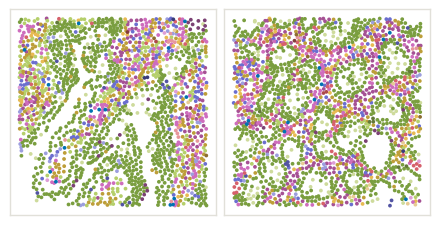

Loadings agree with the PCA (share of rules): {'PC1': np.float64(1.0), 'PC2': np.float64(1.0)}
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_loadings\rule_space_Duodenum_Pathological_loadings.pdf
saved pc_1, pc_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_loadings


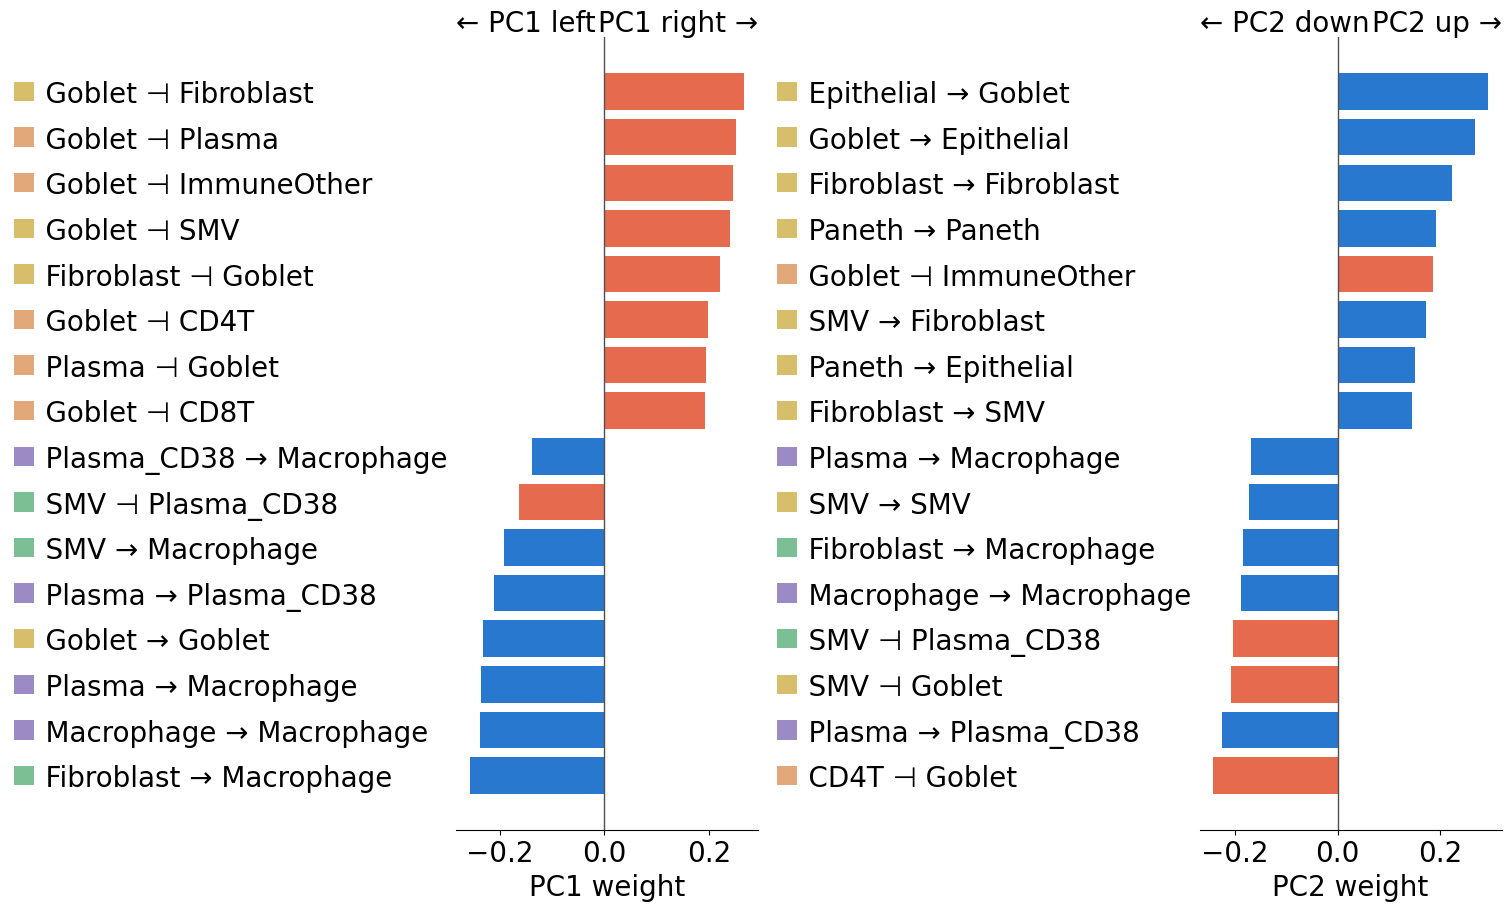

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_pca\cells.pdf


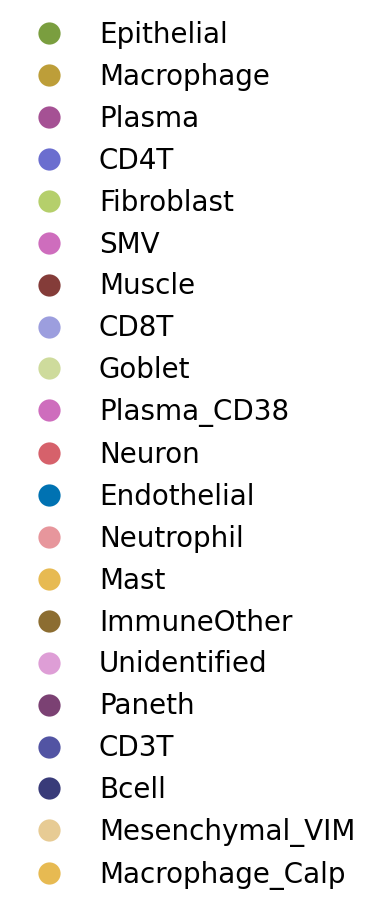

In [9]:
rule_space("Duodenum", "Pathological score", pc="PC2")

### Duodenum · Pathological score · without outliers

Duodenum, Control vs Severe: 62 FOVs x 63 columns  |  PC1 16.0%  PC2 9.1%
Duodenum, Control vs Severe: 3 of 62 FOVs sit more than 4x the usual 2.34 out from the middle
  GVHD_57_FOV_4              6.1x
  GVHD_57_FOV_3              6.0x
  GVHD_57_FOV_2              4.6x
Duodenum, Control vs Severe: 59 FOVs x 75 columns  |  PC1 11.3%  PC2 7.1%
Duodenum, Control vs Severe, cell counts without Muscle: 59 FOVs x 31 columns  |  PC1 68.9%  PC2 10.2%
Control vs Severe AUC per PC:
     Rules  Cells
PC1   0.87    0.9
PC2   0.63    0.7
Agreement, rule PCs (rows) with cell PCs (columns), |rho|:
      PC1   PC2
PC1  0.72  0.25
PC2  0.15  0.11
  pair: Control_01_FOV_3 + Control_08_FOV_1  (0.33 apart, nothing else within 1.22)
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_no_outliers_rules_vs_cells\rule_space_Duodenum_Pathological_no_outliers_rules_vs_cells.pdf
saved pca_1, pca_2 in C:\Users\Owner\Documents\script-rul

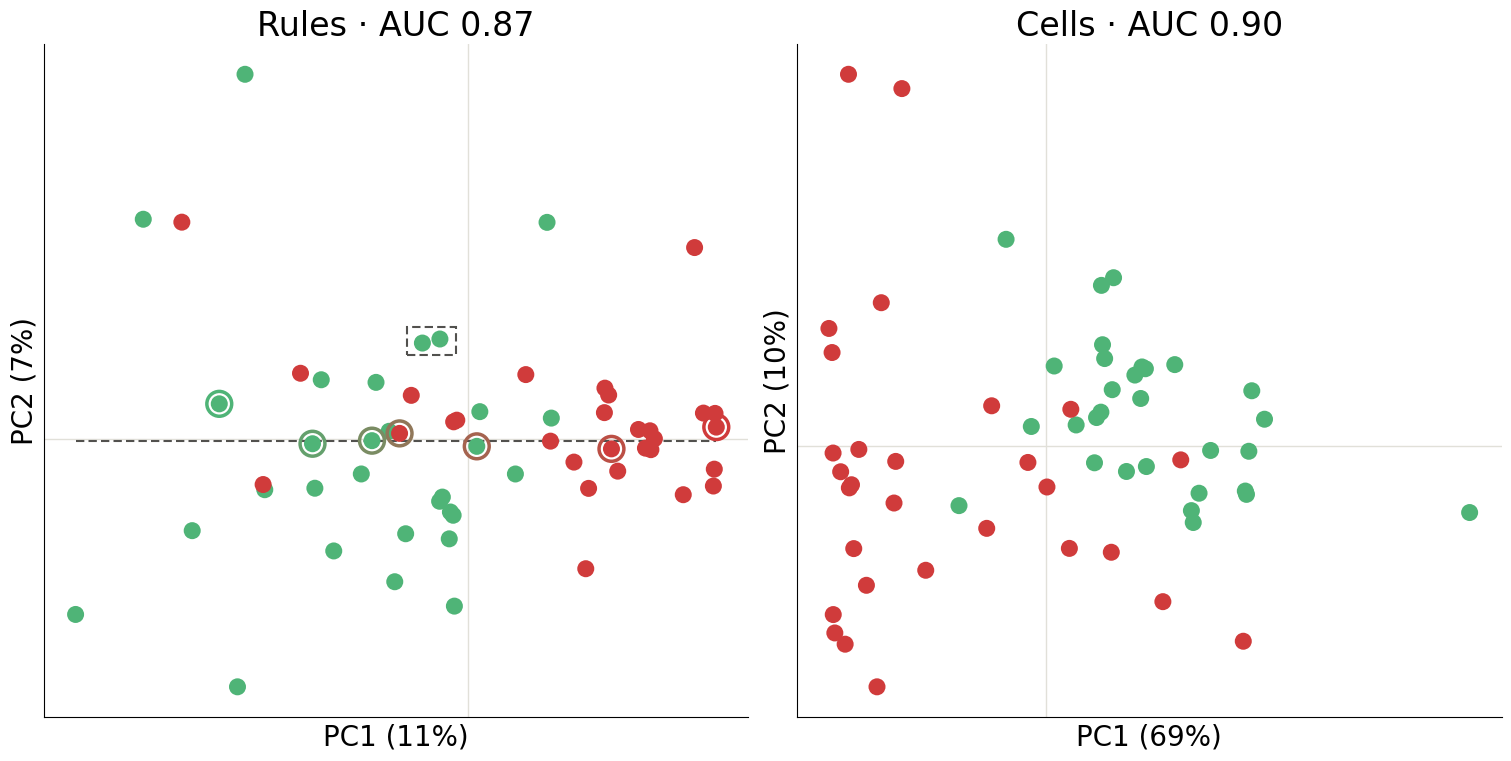

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_no_outliers_pca\pca.pdf


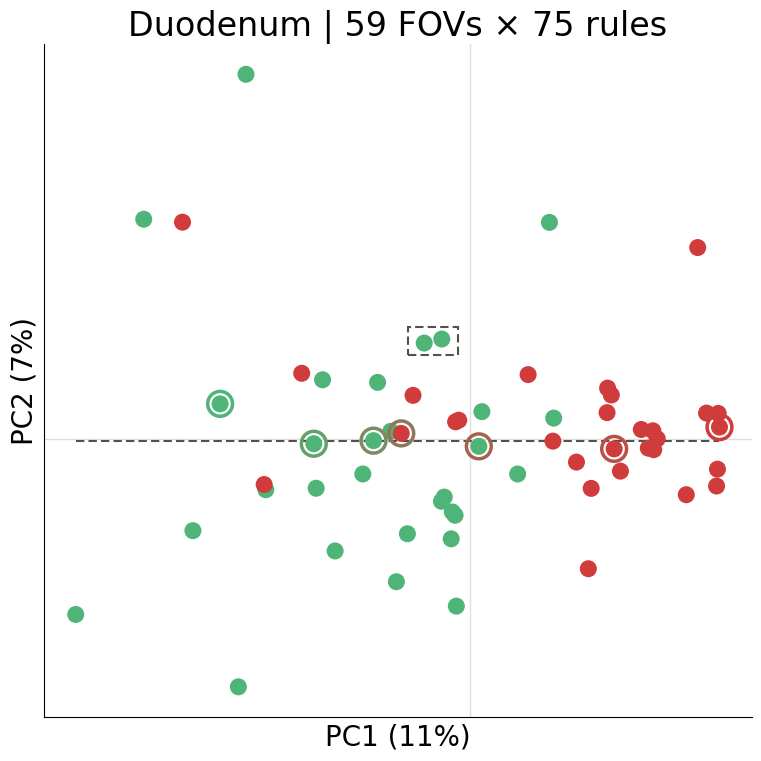

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_no_outliers_spread_maps\rule_space_Duodenum_Pathological_no_outliers_spread_maps.pdf
saved map_1, map_2, map_3, map_4, map_5, map_6, map_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_no_outliers_spread_maps


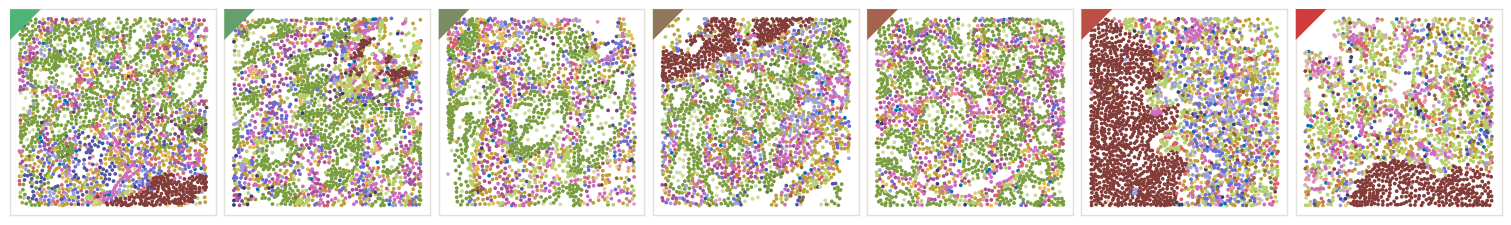

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_no_outliers_pair_maps\rule_space_Duodenum_Pathological_no_outliers_pair_maps.pdf
saved map_1, map_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_no_outliers_pair_maps


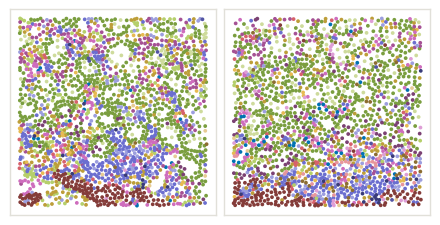

Loadings agree with the PCA (share of rules): {'PC1': np.float64(1.0), 'PC2': np.float64(1.0)}
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_no_outliers_loadings\rule_space_Duodenum_Pathological_no_outliers_loadings.pdf
saved pc_1, pc_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_no_outliers_loadings


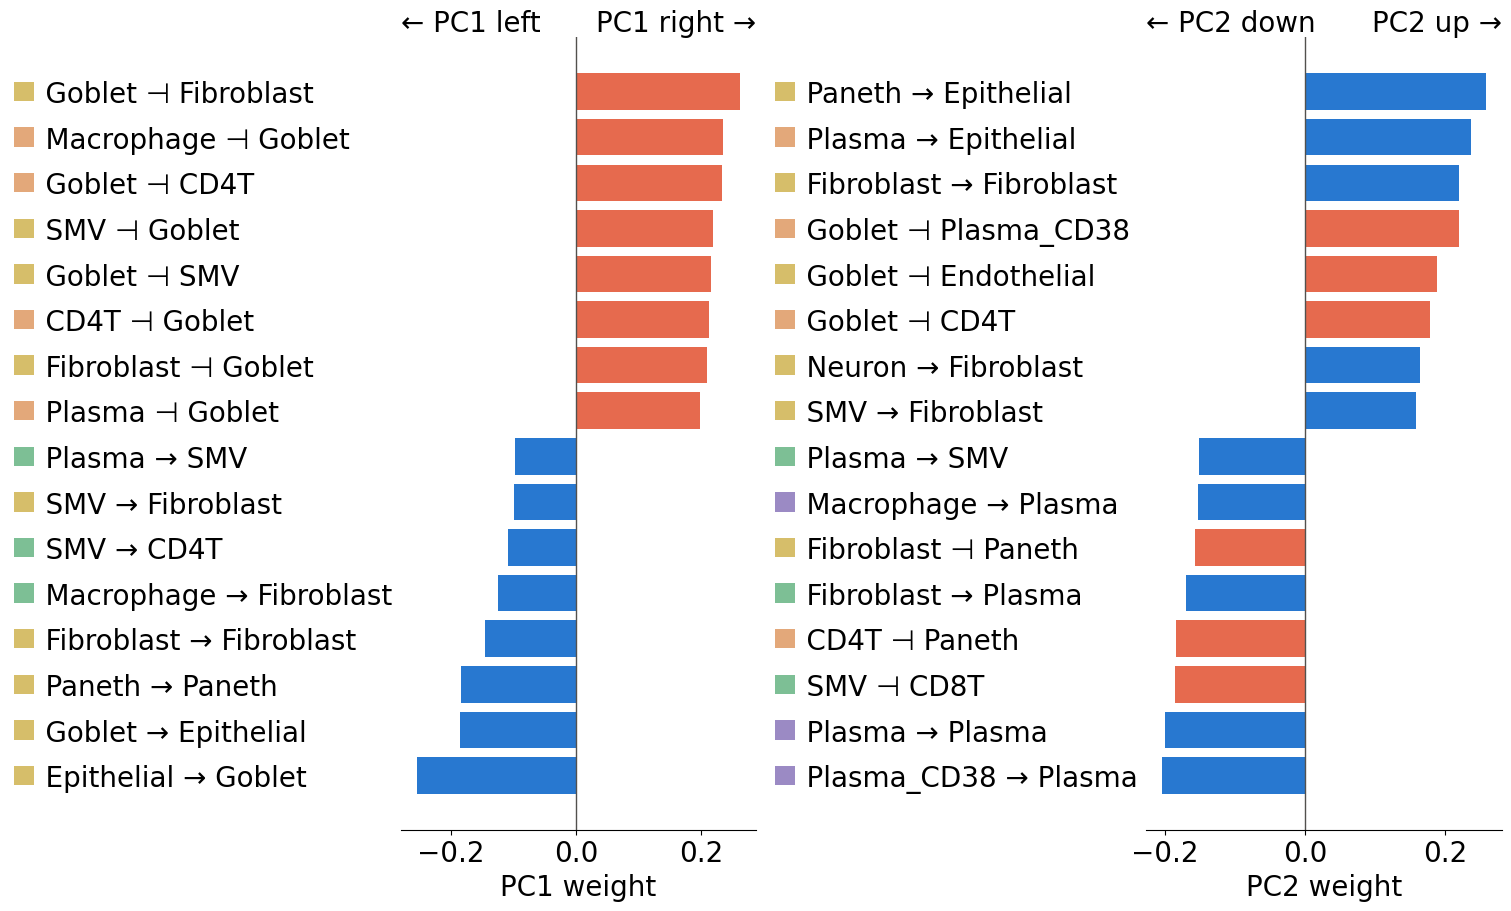

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_space_Duodenum_Pathological_no_outliers_pca\cells.pdf


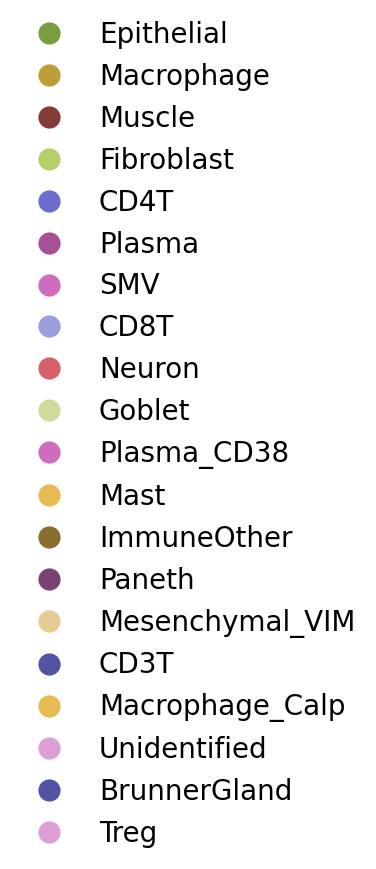

In [10]:
rule_space("Duodenum", "Pathological score", far=4, mark_pair=True)